<img width="1600" height="436" alt="Logo + Title+ Slogan Modified (Updated)" src="https://github.com/user-attachments/assets/e8bda4e2-6039-45f9-ab40-070ea569c98b" />

![Robotics Dojo Banner](https://github.com/user-attachments/assets/e8bda4e2-6039-45f9-ab40-070ea569c98b)

# Waste Management AI Training Notebook

**Purpose:** This notebook is used to train an Object-Detection Model (YOLO26) for use on the Raspberry Pi. 

### Prototype classes
- `organic` → e.g.  **watermelon**
- `plastic` e.g.  **bottle**
- `other` →  e.g. **clothing, metals, etc**

### Pipeline Overview
1. Dataset Curation: Data + Labels
2. train/val/test split
3. Pretrained YOLO → training
4. Validation + error analysis
5. Model Conversions & exports
6. Deployable for the Raspberry Pi


## 0. Imports and project configuration

This cell creates the folders used by the notebook and defines the three classes.

Class IDs must remain consistent:
- `0 = organic`
- `1 = plastic`
- `2 = other`


In [14]:
from pathlib import Path
import random
import shutil
import yaml
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os


# Fixes Hailo's DFC's protobuf issue
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"


# PROJECT = Path.cwd() / "rdj2026-v2i-yolov8_data"
PROJECT = Path("rdj2026-v2i-yolov8_data")
RAW_DIR = PROJECT / "raw"
DATASET_DIR = PROJECT
EXPORT_DIR = PROJECT / "exports"

for p in [RAW_DIR, DATASET_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

CLASSES = ["metal", "organic", "plastic"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

SEED = 82
random.seed(SEED)
np.random.seed(SEED)

print("Project:", PROJECT)
print("Classes:", CLASS_TO_ID)


Project: rdj2026-v2i-yolov8_data
Classes: {'metal': 0, 'organic': 1, 'plastic': 2}


## 1. Dataset Curation

We use a dataset that was prepared by the Robotics Dojo Interns 2026


In [15]:
yaml_path = DATASET_DIR / "data.yaml"

print(yaml_path.read_text())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['metal', 'organic', 'plastic']

roboflow:
  workspace: nikita-kamau
  project: rdj2026
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/nikita-kamau/rdj2026/dataset/2


### Inspect the data before training

Quick sanity check to ensure the dataset is okay to proceed


In [16]:
# Add Code here

## 2. train/validation/test folders

Ultralytics YOLO expects images and matching label files.

Each label line is:

`class_id x_center y_center width height`

with all coordinates normalized from 0 to 1.


In [17]:
# Add Code here

### Split the dataset

We create:
- 70% training
- 20% validation
- 10% test

The test set is kept separate and should only be used for the final evaluation.


In [18]:
# Add code here

# Since the provided dataset already is split, this step is unnecessary

### Check class balance

A model can look good overall while performing badly on one class.

We count labels for each class before training.


In [19]:
# Check Class balance

from collections import Counter

counts = Counter()

for split in ["train", "val", "test"]:
    for label_file in (DATASET_DIR / split / "labels").glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[CLASSES[class_id]] += 1

print("Object counts:")
for name in CLASSES:
    print(f"{name:10s}: {counts[name]}")

Object counts:
metal     : 535
organic   : 919
plastic   : 605


### Visual sanity check

Before training, display a few training images with their bounding boxes.

If the boxes or class IDs are wrong, **stop here and fix the dataset**.


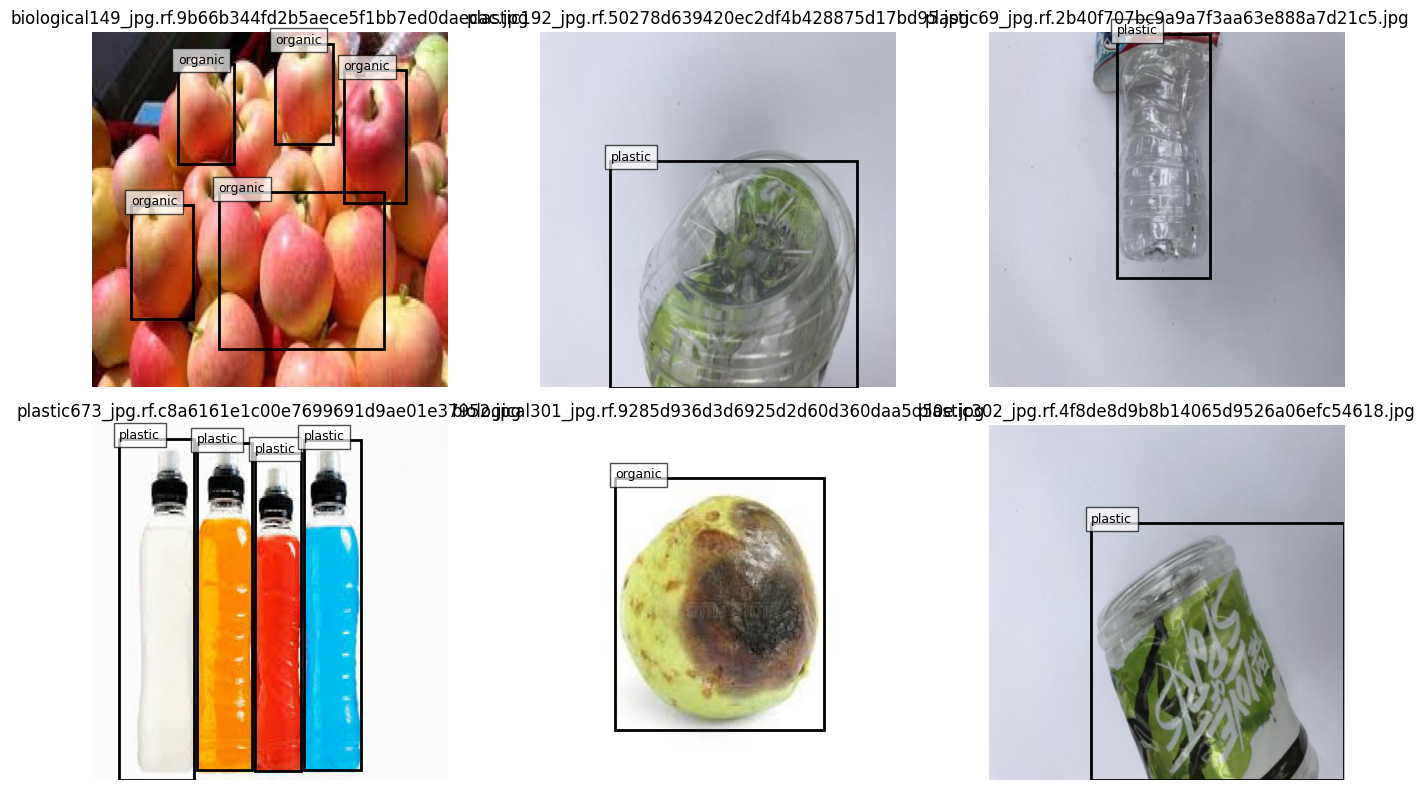

In [20]:
def show_samples(split="train", n=6):
    image_dir = DATASET_DIR / split / "images"
    images = list(image_dir.glob("*"))
    random.Random(SEED).shuffle(images)
    images = images[:n]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()

    for ax, img_path in zip(axes, images):
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(img_path.name)
        ax.axis("off")

        label_path = DATASET_DIR / split / "labels" / f"{img_path.stem}.txt"
        if label_path.exists():
            W, H = img.size
            for line in label_path.read_text().splitlines():
                cls, xc, yc, w, h = map(float, line.split()[:5])
                x1 = (xc - w/2) * W
                y1 = (yc - h/2) * H
                bw = w * W
                bh = h * H
                rect = plt.Rectangle((x1, y1), bw, bh, fill=False, linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1, CLASSES[int(cls)], fontsize=9,
                        bbox=dict(facecolor="white", alpha=0.7))

    plt.tight_layout()
    plt.show()

show_samples()


## 3. Train a small pretrained YOLO model

We start with a **small pretrained detection model** so the model can train quickly.

Training Settings:
- `epochs=30`
- batch



### ML Flow Integration

In [21]:
# !pip -q install mlflow

In [22]:
# !pip -q install jupyter-server-proxy

In [23]:
from ultralytics import YOLO, settings
import time


# Enable MLflow integration
# settings.update({"mlflow": True})

# Define the macro project grouping
experiment_group = "waste_detector_v1"

# Dynamically generate a unique run name
version = "v0.1.0"
arch = "yolo26n"
timestamp = time.strftime("%Y-%m-%d_%H-%M")
run_name = f"{version}_{arch}_{timestamp}-alpha"

model = YOLO(f"{arch}.pt")

print(run_name)

v0.1.0_yolo26n_2026-11-19_23-31-alpha


### Start Training

In [24]:


results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=-1,
    patience=10,
    project=str(PROJECT / experiment_group), # ML Flow Experiment Name
    name=run_name, # ML Flow run name
    exist_ok=False,
)

print("Training finished.")


Ultralytics 8.4.215 🚀 Python-3.10.14 torch-2.3.1 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=rdj2026-v2i-yolov8_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v0.1.0_yolo26n_2026-11-19_23-31-alpha, n

### ML Flow Dashboard

mlflow server --host 0.0.0.0 --port 5000

URL: https://subdomain.trycloudflare.com/proxy/5000/

## 4. Validate the trained model (val set)

Validation answers:

> "How well does the model detect the classes on images it did not train on?"

Pay attention to:
- mAP50
- mAP50-95
- precision
- recall
- per-class performance


In [25]:
# best_model_path = PROJECT / "training_runs" / "production" / "weights" / "best.pt"
# best_model_path = Path('/workspace/runs/detect/rdj2026-v2i-yolov8/waste_detector_v1/v0.1.0_yolo26n_2026-10-07_07-08-alpha') / "weights" / "best.pt"
best_model_path = Path(f'/workspace/runs/detect/rdj2026-v2i-yolov8_data/{experiment_group}/{run_name}') / "weights" / "best.pt"
best_model = YOLO(str(best_model_path))

print(f'Best Model Path: {best_model_path}')
print(yaml_path)

metrics = best_model.val(
    data=str(yaml_path),
    split="val",
    imgsz=640,
)

print("mAP50-95:", metrics.box.map)
print("mAP50:", metrics.box.map50)
print("Per-class mAP50-95:", metrics.box.maps)


Best Model Path: /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.pt
rdj2026-v2i-yolov8_data/data.yaml
Ultralytics 8.4.215 🚀 Python-3.10.14 torch-2.3.1 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1309.1±440.3 MB/s, size: 28.7 KB)
val: Scanning /workspace/rdj2026-v2i-yolov8_data/valid/labels.cache... 304 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 304/304 44.0Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 3, len(boxes) = 523. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 9.6it/s 2.0s<0.1s
            

### Test on completely unseen images (test set)

The test set should be treated as the final exam.


In [26]:
test_metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
)

print("TEST mAP50-95:", test_metrics.box.map)
print("TEST mAP50:", test_metrics.box.map50)
print("TEST per-class mAP50-95:", test_metrics.box.maps)


Ultralytics 8.4.215 🚀 Python-3.10.14 torch-2.3.1 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1219.2±375.5 MB/s, size: 30.0 KB)
val: Scanning /workspace/rdj2026-v2i-yolov8_data/test/labels.cache... 153 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 153/153 14.0Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 269. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 6.1it/s 1.6s0.2s
                   all        153        269      0.846      0.694       0.81       0.55
                 metal         51         74      0.958      0.905      0.975      0.732
      

### Run inference on test images

> **Does the model put the correct box around the correct waste object?**


In [27]:
test_images = list((DATASET_DIR / "test" / "images").glob("*"))

# print(test_images)

predictions = best_model.predict(
    source=[str(p) for p in test_images[:12]],
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(PROJECT / "predictions"),
    name="test_predictions",
    exist_ok=True,
)

print("Prediction images saved to:", PROJECT / "predictions" / "test_predictions")



0: 640x640 1 plastic, 0.9ms
1: 640x640 3 organics, 0.9ms
2: 640x640 1 plastic, 0.9ms
3: 640x640 1 plastic, 0.9ms
4: 640x640 1 plastic, 0.9ms
5: 640x640 1 organic, 0.9ms
6: 640x640 1 metal, 0.9ms
7: 640x640 1 plastic, 0.9ms
8: 640x640 2 organics, 0.9ms
9: 640x640 (no detections), 0.9ms
10: 640x640 1 metal, 0.9ms
11: 640x640 6 metals, 0.9ms
Speed: 0.7ms preprocess, 0.9ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /workspace/runs/detect/rdj2026-v2i-yolov8_data/predictions/test_predictions
Prediction images saved to: rdj2026-v2i-yolov8_data/predictions/test_predictions


## 5. Model Conversions

The important artifact is:

`best.pt`

Also save:
- `data.yaml`
- the dataset
- training results
- this notebook
- a requirements file
- a README describing the experiment

This makes the experiment reproducible on another computer.


In [28]:
# Copy the best model into a simple export location.
rpi_deployable_model = EXPORT_DIR / f"{run_name}.pt"
shutil.copy2(best_model_path, rpi_deployable_model)

# Copy data.yaml
shutil.copy2(yaml_path, EXPORT_DIR / "data.yaml")

print("RPi Deployable model:", rpi_deployable_model)


RPi Deployable model: rdj2026-v2i-yolov8_data/exports/v0.1.0_yolo26n_2026-11-19_23-31-alpha.pt


### Convert model to NCNN Format

Ultralytics officially recommends NCNN as the highest-performing option for ARM-based embedded CPUs

https://docs.ultralytics.com/guides/raspberry-pi


In [29]:
# Load your trained YOLO26n PyTorch model
# model = YOLO("yolo26n.pt")
model = YOLO(best_model_path)

# Export to highly optimized NCNN format
model.export(format="ncnn")

Ultralytics 8.4.215 🚀 Python-3.10.14 torch-2.3.1 CPU (AMD EPYC 9354 32-Core Processor)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)

NCNN: starting export with NCNN 1.0.20261020 and PNNX 20260526...


pnnxparam = /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model/model.pnnx.param
pnnxbin = /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model/model.pnnx.bin
pnnxpy = /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model/model_pnnx.py
pnnxonnx = /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model/model.pnnx.onnx
ncnnparam = /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model/model.ncnn.param
ncnnbin = /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model/model.ncnn.bin
ncnnpy = /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0

NCNN: export success ✅ 4.0s, saved as '/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model' (9.3 MB)

Export complete (4.2s)
Results saved to /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model
Predict:         yolo predict task=detect model=/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model imgsz=640 
Validate:        yolo val task=detect model=/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model imgsz=640 data=rdj2026-v2i-yolov8_data/data.yaml 
Visualize:       https://netron.app


'/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_ncnn_model'

### Convert model to ONNX Format

In [30]:
# Export to ONNX format
model.export(format="onnx")

Ultralytics 8.4.215 🚀 Python-3.10.14 torch-2.3.1 CPU (AMD EPYC 9354 32-Core Processor)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)

ONNX: starting export with onnx 1.16.0 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.2s, saved as '/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.onnx' (9.4 MB)

Export complete (3.5s)
Results saved to /workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.onnx
Predict:         yolo predict task=detect model=/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.onnx imgsz=640 
V

'/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.onnx'

### Convert model to HEIF Format

This is for use specifically with the AI HAT+ (Hailo-8L) accelerator

- HEIF: Hailo Executable Format

In [31]:
# Install Hailo's Dependencies 
# Download Hailo Dataflow Compiler from Hailo's Developer Zone
# https://hailo.ai/developer-zone/software-downloads
!pip -q install hailo_dataflow_compiler-3.34.0-py3-none-linux_x86_64.whl
# !pip install --force-reinstall protobuf==3.20.0

In [32]:
!export CUDA_VISIBLE_DEVICES=0
!nvidia-smi --query-gpu=index,name,memory.used,memory.total,compute_cap --format=csv
!python3 -c "import tensorflow as tf; print('TF:', tf.__version__, 'CUDA:', tf.test.is_built_with_cuda(), 'GPUs:', tf.config.list_physical_devices('GPU'))"
!hailo --version

index, name, memory.used [MiB], memory.total [MiB], compute_cap
0, NVIDIA RTX 4500 Ada Generation, 1590 MiB, 24570 MiB, 8.9
1, NVIDIA RTX 4500 Ada Generation, 14248 MiB, 24570 MiB, 8.9
E0000 00:00:1795131266.243919    2248 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795131266.248568    2248 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1795131268.436980    2248 gpu_device.cc:2344] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
TF: 2.18.0 CUDA: True GPUs: []
[info] No GPU chosen and no suitable GPU found, falling back to 

In [33]:
# Export to HEIF format
# (Note: This requires the Hailo Dataflow Compiler toolchain installed)

import os
os.environ.setdefault("USER", "root")

model.export(format="hailo")

Ultralytics 8.4.215 🚀 Python-3.10.14 torch-2.3.1 CPU (AMD EPYC 9354 32-Core Processor)
WARNING ⚠️ hailo export requires INT8 quantization, enabling it.
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)
[info] No GPU chosen and no suitable GPU found, falling back to CPU.


E0000 00:00:1795131278.265905      76 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795131278.270014      76 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026/11/19 23:34:40 WARNING mlflow.utils.autologging_utils: MLflow keras autologging is known to be compatible with 3.7.0 <= keras, but the installed version is 3.5.0. If you encounter errors during autologging, try upgrading / downgrading keras to a compatible version, or try upgrading MLflow.
2026/11/19 23:34:40 INFO mlflow.tracking.fluent: Autologging successfully enabled for keras.
2026/11/19 23:34:40 WARNING mlflow.utils.autologging_utils: MLflow tensorflow autologging is known to be compatible with 2.18.1 <= tensorflow, but the installed version is 2.18.0. If you encounter errors during autologging, try upgrading / downgrading tensor

[warning] Cannot use graphviz, so no visualizations will be created
Hailo: collecting INT8 calibration images from 'data=coco128.yaml'
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1746.0±680.8 MB/s, size: 45.5 KB)
val: Scanning /workspace/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 12.5Mit/s 0.0s
WARNING ⚠️ Hailo: >300 images recommended for INT8 calibration, found 128 images.
WARNING ⚠️ 
Hailo level-2 optimization will use 128 calibration images. Hailo recommends at least 1,024 representative images for best accuracy. Pass data="path/to/dataset.yaml". See https://docs.ultralytics.com/integrations/hailo#export-a-hailo-hef-model

ONNX: starting export with onnx 1.16.0 opset 11...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.7s, saved as '/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.onnx' (9.4 MB)
[info] Translation started on ONNX 

Calibration: 100%|██████████| 64/64 [00:59<00:00,  1.07entries/s]


[info] Model Optimization Algorithm Statistics Collector is done (completion time is 00:01:00.92)
[info] Starting Fix zp_comp Encoding
[info] Model Optimization Algorithm Fix zp_comp Encoding is done (completion time is 00:00:00.00)
[info] Starting Matmul Equalization
[info] Model Optimization Algorithm Matmul Equalization is done (completion time is 00:00:00.04)
[info] Starting MatmulDecomposeFix
[info] Model Optimization Algorithm MatmulDecomposeFix is done (completion time is 00:00:00.00)
[info] activation fitting started for best/reduce_sum_softmax1/act_op
[info] activation fitting started for best/reduce_sum_softmax2/act_op
[info] Finetune encoding skipped
[info] Bias Correction skipped
[info] Adaround skipped
[info] Starting Quantization-Aware Fine-Tuning
[info] Using dataset with 128 entries for finetune


2026/11/19 23:37:08 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '8e1ac4a46e4344aeadada9635a075963', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current tensorflow workflow
2026/11/19 23:37:08 WARNING mlflow.tensorflow: Encountered unexpected error while inferring batch size from training dataset: 'Distiller' object has no attribute 'input_shape'
2026/11/19 23:37:10 WARNING mlflow.utils.validation: Param value '[{'optimizer': <keras.src.optimizers.adam.Adam object at 0x7f5c36483850>, 'weights': [<KerasVariable...' (22160 characters) is truncated to 6000 characters to meet the length limit.


... (10 outputs left out)

[info] Model Optimization Algorithm Quantization-Aware Fine-Tuning is done (completion time is 00:12:22.10)
[info] Starting Layer Noise Analysis


Full Quant Analysis: 100%|██████████| 2/2 [03:47<00:00, 113.99s/iterations]


[info] Model Optimization Algorithm Layer Noise Analysis is done (completion time is 00:03:51.44)
[info] Output layers signal-to-noise ratio (SNR): measures the quantization noise (higher is better)
[info] 	best/output_layer1 SNR:	16.78 dB
[info] 	best/output_layer3 SNR:	18.42 dB
[info] 	best/output_layer5 SNR:	20.47 dB
[info] 	best/output_layer2 SNR:	31.26 dB
[info] 	best/output_layer4 SNR:	29.37 dB
[info] 	best/output_layer6 SNR:	23.92 dB
[info] Model Optimization is done
[info] To achieve optimal performance, set the compiler_optimization_level to "max" by adding performance_param(compiler_optimization_level=max) to the model script. Note that this may increase compilation time.
[info] Loading network parameters
[info] Starting Hailo allocation and compilation flow
[info] Building optimization options for network layers...
[info] Successfully built optimization options - 6s 978ms
[info] Trying to compile the network in a single context
[info] Single context flow failed: Recoverable 

'/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best_hailo_model'

#### Issues with Hailo Export

export failure 11.5s: /lib/x86_64-linux-gnu/libc.so.6: version `GLIBC_2.34' not found

- The error version GLIBC_2.34 not found means that the Hailo Dataflow Compiler (DFC) or its compiled dependencies were built for a newer Linux operating system (like Ubuntu 22.04 or newer), but you are running them on an older host OS (like Ubuntu 20.04 or Debian 11) that only has an older version of glibc (such as GLIBC 2.31 or 2.33).
- Because glibc is the core C library of the operating system, you cannot safely upgrade it on your current system without breaking the entire OS.

#### Solutions

1. Hailo Model Zoo CLI (Ubuntu Compatible)
2. Hailo SW Suite Docker

## 6. Raspberry Pi Deployment

Robotics Dojo provides a ROS2 Package that utilizes the trained model, with support for both CPU-only and Accelerator-enabled inference:

- Use NCNN for CPU-Only inference
- Use HEIF for Accelerator-enabled inference

More info about the Robotics Dojo ROS2 Package

In [34]:
import zipfile

zip_path = EXPORT_DIR / f"rpi_models_{run_name}.zip"

best_ncnn_model_dir = Path(f'/workspace/runs/detect/rdj2026-v2i-yolov8_data/{experiment_group}/{run_name}/weights/best_ncnn_model')
best_onnx_model = f'/workspace/runs/detect/rdj2026-v2i-yolov8_data/{experiment_group}/{run_name}/weights/best.onnx'
best_hef_model = f'/workspace/runs/detect/rdj2026-v2i-yolov8_data/{experiment_group}/{run_name}/weights/best_hailo_model/best.hef'


# shutil.copy2(best_ncnn_model_dir, EXPORT_DIR) # Doesn't work for directories
shutil.copytree(best_ncnn_model_dir, EXPORT_DIR / f'{run_name}_ncnn/', dirs_exist_ok=True)
shutil.copy2(best_onnx_model, EXPORT_DIR / f'{run_name}.onnx')
shutil.copy2(best_hef_model, EXPORT_DIR / f'{run_name}.onnx')

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:

    z.write(rpi_deployable_model, rpi_deployable_model.relative_to(PROJECT))
    # z.write(best_ncnn_model_dir)
    # z.write(best_onnx_model)
    # z.write(EXPORT_DIR / f'{run_name}_ncnn/')
    z.write(EXPORT_DIR / f'{run_name}.onnx')
    z.write(EXPORT_DIR / f'{run_name}.hef')
    z.write(EXPORT_DIR / "data.yaml")

    # Handle NCNN dir
    # rglob("*") recursively searches all files and folders
    ncnn_dir = Path(EXPORT_DIR / f'{run_name}_ncnn/')
    for file in ncnn_dir.rglob("*"):
        if file.is_file():
            # Relative path preserves the inner folder structure cleanly
            # z.write(file, arcname=file.relative_to(ncnn_dir))
            z.write(file)
    


print("Package created:", zip_path)


FileNotFoundError: [Errno 2] No such file or directory: '/workspace/runs/detect/rdj2026-v2i-yolov8_data/waste_detector_v1/v0.1.0_yolo26n_2026-11-19_23-31-alpha/weights/best.onnx'

# GLHF ;)